In [61]:
from PIL import Image
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
path = ROOT / "data" / "corrected.tif"

(684, 428) (684, 428)


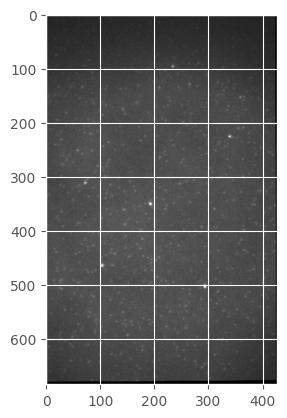

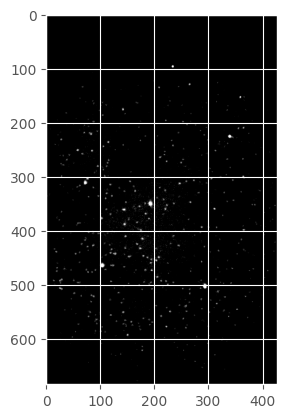

In [62]:
with Image.open(path) as image:
    image.seek(0)
    frame = np.array(image)

left = frame[:, :428]    # columns 0–427
right = frame[:, 428:]  # columns 428–855
print(left.shape, right.shape)  # both (684, 428)
right_centred = np.clip(right.astype(np.float32) - right.mean(), 0, right.max())

plt.imshow(right, cmap="gray", vmin=300, vmax=1500)
plt.show()
plt.imshow(right_centred, cmap="gray", vmin=100, vmax=300)
plt.show()

In [63]:
from picasso.localize import localize_frames

In [64]:
# Detection settings: starting values to explore, not calibrated thresholds.
params = {
    "Box Size": 7,
    "Min. Net Gradient": 3000,
}

# Placeholder camera conversion values for exploring spot positions.
# Replace these with your camera's calibration before interpreting photon counts.
camera_info = {
    "Baseline": 0,
    "Sensitivity": 1.0,
    "Gain": 1,
    "Pixelsize": 117,  # nm; your TIFF metadata says approximately 0.117 µm
}

right_locs = localize_frames(
    right_centred[np.newaxis, :, :],
    info=None,
    params=params,
    camera_info=camera_info,
    fitting_method="gausslq",
    threaded=False,
)

print(f"Right: {len(right_locs)} localisations")

right_locs.head()

Right: 65 localisations


,frame,x,y,photons,sx,sy,bg,lpx,lpy,ellipticity,net_gradient,iterations,chi_square
0,0,233.424454,96.423996,6401.729004,1.402261,1.470400,8.385703,0.024327,0.025462,0.046340,8845.665039,3,4867.371582
1,0,264.431732,129.304092,3925.003662,1.550841,1.570005,20.082893,0.036502,0.036938,0.012207,5014.127930,4,7850.594727
2,0,66.921204,133.955490,2372.154053,1.500084,1.409719,4.283779,0.042977,0.040483,0.060240,3304.803467,2,25055.150391
3,0,208.206024,135.263168,3493.393799,1.595883,1.566807,13.641798,0.039108,0.038418,0.018219,4172.270996,3,7667.213867
4,0,358.085327,153.142441,4031.821045,1.254461,1.529744,10.744258,0.028032,0.033901,0.179953,5932.914551,2,28161.136719


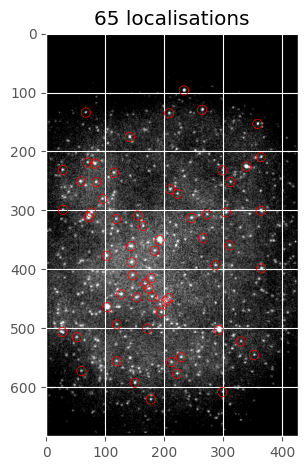

In [65]:
vmin, vmax = np.percentile(right_centred, [1, 99.8])
plt.imshow(right_centred, cmap="gray", vmin=vmin, vmax=vmax)

plt.scatter(
    right_locs["x"], right_locs["y"],
    s=45, facecolors="none", edgecolors="red",
)
plt.title(f"{len(right_locs)} localisations")

plt.tight_layout()
plt.show()